# Math 300, Fall 2026 — Project 1
## Root-Finding and Fixed-Point Iteration

**Name:** Arslan Sanabayev

Each substantial experiment is organized as **Prediction → Implementation → Experiment → Analysis**. The purely theoretical parts (1(a), 1(b), 3(a), 3(b)) are the Prediction stage for the experiments that follow them, and each part (f) is a verification.

### Use of generative AI
I used Claude (Anthropic) as a computational assistant throughout this project.

* **Checking my own work.** I solved 1(a) by hand ($n = 27$) and asked Claude to check it. It confirmed the answer and pointed out that the other common convention, $|p_n-p|\le(b-a)/2^n$, gives $28$ for the same midpoint, so I state my convention explicitly.
* **Discussing theory.** For 1(b), Claude first gave a Taylor-series derivation of quadratic convergence. I asked for an argument that applies the convergence theorem directly, which is what part (b) asks for. I also asked whether "at least quadratic" corresponds to big-$\Omega$. Claude explained that it is big-$O$ on the error ($|e_{n+1}|=O(|e_n|^2)$), and that here the order is exactly 2 because $f''(p)\ne0$. I added the order-estimate formula for $\alpha$ from class.
* **My own decisions.** The assignment writes $\log(x)$ without a base. I chose $\ln$, because with $\log_{10}$ the interval $[28,30]$ has no sign change and the reference value is not a root (checked in Problem 1).
* **Code, tables, figures and drafts.** Claude wrote most of the Julia code, adapted from the class functions `bisection_method` and `newton_method` and from the Newton-fractal example. It also produced the formatted tables and plots and drafted the analysis text. I reviewed all of it and checked that every number quoted in the text matches the printed output.
* **Formulas.** The copy of the assignment I first gave Claude had garbled formulas for $g_1,\dots,g_4$. Claude reconstructed them, and I compared the reconstruction against the original PDF. They match.

I treated AI output as something to test, not to trust. Parts 1(f), 2(f) and 3(f) each document a specific AI claim, how I verified it independently (high-precision arithmetic, an exact factorization, companion-matrix eigenvalues, finite differences), and in 1(f) a claim that turned out to be **wrong** and how I corrected it.


In [1]:
using Plots
using Printf          # for formatted tables
using LinearAlgebra   # for eigvals in 2(f)

---
# Problem 1 — Comparison of Root-Finding Methods

$$
f(x) = x - \ln(x) - 25, \qquad x > 0,
$$
and we approximate the larger root, with reference value $p = 28.344430557890227$.

Derivatives used below:
$$
f'(x) = 1 - \frac{1}{x}, \qquad f''(x) = \frac{1}{x^2} > 0 .
$$
So $f$ is convex, decreasing on $(0,1)$ and increasing on $(1,\infty)$, with minimum $f(1) = -24$. It has exactly two roots: a tiny one near $e^{-25}\approx 1.4\times10^{-11}$ and the larger one near $28.34$.

**Interpretation of $\log$.** The assignment writes $f(x) = x - \log(x) - 25$ without stating the base. I assumed $\log$ means the **natural logarithm** $\ln x$, because the base-10 reading does not work with the given data:
* with $\log_{10}$, $f(28) = 28 - 1.447 - 25 \approx 1.55$ and $f(30) \approx 3.52$ are both positive, so $[28,30]$ does **not** bracket a root and bisection cannot start;
* with $\log_{10}$, the reference value is not a root: $f(28.3444) \approx 1.89 \neq 0$.

With $\ln$, $f(28)<0<f(30)$ and $f(p)\approx 0$, so $\ln$ is consistent with the problem. The check is in the next cell. (In Julia, `log(x)` is $\ln x$ and `log10(x)` is $\log_{10} x$.)

In [2]:
# Which logarithm? Compare ln (log in Julia) with base-10 (log10)
f_ln(x)    = x - log(x) - 25
f_log10(x) = x - log10(x) - 25
println("ln:     f(28) = $(f_ln(28)),   f(30) = $(f_ln(30)),   f(p) = $(f_ln(28.344430557890227))")
println("log10:  f(28) = $(f_log10(28)),   f(30) = $(f_log10(30)),   f(p) = $(f_log10(28.344430557890227))")

ln:     f(28) = -0.33220451017520247,   f(30) = 1.5988026183378459,   f(p) = 3.517186542012496e-13


log10:  f(28) = 1.5528419686577806,   f(30) = 3.5228787452803374,   f(p) = 1.89196282149004


In [3]:
f1(x) = x - log(x) - 25;     # log is the natural log ln in Julia
df1(x) = 1 - 1/x;
p_ref = 28.344430557890227;  # reference value given in the assignment

@show f1(28);
@show f1(30);                # opposite signs, so [28, 30] brackets the root

f1(28) = -0.33220451017520247
f1(30) = 1.5988026183378459


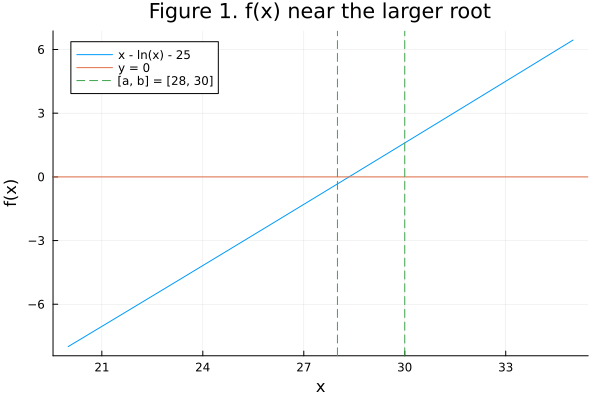

In [4]:
xx = LinRange(20, 35, 200)
plot(xx, f1.(xx), label="x - ln(x) - 25", xlabel="x", ylabel="f(x)")
hline!([0], label="y = 0")
vline!([28, 30], label="[a, b] = [28, 30]", linestyle=:dash)
title!("Figure 1. f(x) near the larger root")

*Figure 1. $f(x)=x-\ln x-25$ on $[20,35]$. $f$ changes sign inside the dashed bracket $[28,30]$, so bisection can start there. The crossing is the larger root $p\approx28.344$.*

## 1(a) Bisection: iterations needed for error $< 10^{-8}$

Using the bound from class: after $n$ bisections of $[a_0, b_0]$, the midpoint is within $\dfrac{b_0-a_0}{2^{n+1}}$ of the root. Requiring this to be smaller than $\tau = 10^{-8}$:
$$
\frac{b_0 - a_0}{2^{n+1}} < \tau
\iff n > \log_2\!\left(\frac{b_0-a_0}{\tau}\right) - 1
= \log_2\!\left(\frac{2}{10^{-8}}\right) - 1
\approx 27.58 - 1 = 26.58 .
$$
So
$$
\boxed{n = 27}
$$

**Check:**
* $n = 27$: $\dfrac{2}{2^{28}} \approx 7.45\times10^{-9} < 10^{-8}$ ✓
* $n = 26$: $\dfrac{2}{2^{27}} \approx 1.49\times10^{-8} > 10^{-8}$ ✗

**Convention note.** Some texts label the first midpoint $p_1$ and use $|p_n - p| \le \dfrac{b-a}{2^n}$, which gives $n = 28$. Both conventions refer to the same point: the 28th midpoint, computed after 27 bisections. In the code below, the loop counter `n` labels the midpoints ($p_1$ is the first midpoint), so the guarantee shows up at **$n = 28$** in the tables.

In [5]:
a = 28;
b = 30;
τ = 10^(-8);
@show log2((b - a)/τ) - 1;     # criterion from class (Oct 1): n ≥ this
@show (b - a)/2^(27 + 1);      # error bound after 27 bisections: below τ
@show (b - a)/2^(26 + 1);      # error bound after 26 bisections: above τ

log2((b - a) / τ) - 1 = 26.575424759098897
(b - a) / 2 ^ (27 + 1) = 7.450580596923828e-9
(b - a) / 2 ^ (26 + 1) = 1.4901161193847656e-8


## 1(b) Newton's method from $p_0 = 29$: theoretical prediction

**Convergence order.** Newton's method converges quadratically to a simple root, i.e. a root with $f'(p) \neq 0$, provided $p_0$ is sufficiently close. Here
$$
f'(p) = 1 - \frac{1}{p} \approx 1 - \frac{1}{28.34} \approx 0.965 \neq 0,
$$
so $p$ is a simple root and Newton converges **at least quadratically**:
$$
|e_{n+1}| = O\!\left(|e_n|^2\right), \qquad e_n = p_n - p .
$$
Moreover $f''(p) = 1/p^2 \neq 0$, so the convergence is **exactly quadratic** ($\alpha = 2$):
$$
\lim_{n\to\infty}\frac{|e_{n+1}|}{|e_n|^2} = C = \left|\frac{f''(p)}{2f'(p)}\right| = \frac{1}{2p(p-1)} \approx 6.45\times 10^{-4} .
$$

**Correct digits.** If $|e_n| \approx 10^{-k}$, then $|e_{n+1}| \approx C\cdot 10^{-2k}$. So once the iteration is sufficiently close to the root, **the number of correct digits roughly doubles each iteration** (about $1 \to 2 \to 4 \to 8 \to 16$), until it reaches the limit of double precision (about 16 digits). Because $C$ is small here, the improvement should be a bit better than doubling.

**Checking the order from data (used in part d).** If $|e_{n+1}| \approx C|e_n|^\alpha$ and $|e_n| \approx C|e_{n-1}|^\alpha$, dividing the two and taking logs gives
$$
\alpha \approx \frac{\ln|e_{n+1}| - \ln|e_n|}{\ln|e_n| - \ln|e_{n-1}|}.
$$
The constant $C$ cancels. We predict $\alpha \approx 2$.

**Can the order alone tell us how many iterations are needed for an error $< 10^{-8}$?** No. The order only describes how each error relates to the previous one. The actual number of iterations also depends on:
1. **the starting error** $|p_0 - p|$, i.e. how many correct digits we start with;
2. **the asymptotic constant** $C$, which the order does not tell us;
3. **when the asymptotic regime begins.** Quadratic convergence is only guaranteed "sufficiently close" to $p$, and the theorem does not say how close that is.

Two methods with the same order but different $C$ or $p_0$ can need very different numbers of iterations, and one of them may not converge at all.

*Remark (beyond the order alone).* If we *also* use $C\approx6.45\times10^{-4}$ and $|e_0| = |29-p|\approx 0.656$, the estimate $|e_{n+1}|\approx C|e_n|^2$ gives $|e_1|\approx 2.8\times10^{-4}$ and $|e_2|\approx 5\times10^{-11}$, so we expect about **2 iterations**. We test this in part (d).

## 1(c) Bisection on $[28, 30]$

**Prediction.**
* The estimated error $|p_n-p_{n-1}|$ should be exactly $2/2^n$, because $p_{n-1}$ is an endpoint of the current bracket. So it should first drop below $10^{-8}$ at $n=28$, the guaranteed value from (a).
* The actual error is always at most the bound but is *not* monotone (a midpoint can land close to $p$ by luck), so it may drop below $10^{-8}$ earlier.
* Near the root, $f(p_n)\approx f'(p)(p_n-p)$ with $f'(p)\approx0.965$, so the residual should track the actual error closely and be about 3.5% smaller.

**Implementation.** The function follows `bisection_method` from class (Sept 29 / Oct 1), but stores every midpoint $p_1, p_2, \dots$ so we can build the table. It accepts `Float64` or `BigFloat` endpoints.

In [6]:
function bisection_history(f, a, b; nmax=40)
    if (f(a) * f(b) > 0)
        error("The function must have opposite signs at the endpoints of the interval.")
    end
    ps = typeof(float(a + b))[]    # stores p_1, p_2, ...
    for n in 1:nmax
        half_width = (b - a)/2;
        c = a + half_width;        # midpoint p_n
        push!(ps, c)
        if f(c) == 0               # landed exactly on the root
            break
        elseif f(a)*f(c) < 0
            b = c;
        else
            a = c;
        end
    end
    return ps
end

# table: Iteration, p_n, actual error, estimated error, residual
function print_root_table(ps, f, p; nstart=1)
    @printf("%9s  %22s  %12s  %16s  %12s\n", "Iteration", "p_n", "|p_n - p|", "|p_n - p_{n-1}|", "|f(p_n)|")
    for (k, pn) in enumerate(ps)
        n = k - 1 + nstart
        est = k == 1 ? "—" : @sprintf("%.4e", abs(pn - ps[k-1]))
        @printf("%9d  %22.17g  %12.4e  %16s  %12.4e\n", n, pn, abs(pn - p), est, abs(f(pn)))
    end
end

# iteration number at which a sequence first drops below tol
function first_below(v, tol; nstart=1)
    k = findfirst(x -> x < tol, v)
    return k === nothing ? nothing : k - 1 + nstart
end

first_below (generic function with 1 method)

**Experiment.**

In [7]:
ps_bis = bisection_history(f1, 28.0, 30.0; nmax=32)
print_root_table(ps_bis, f1, p_ref)

Iteration                     p_n     |p_n - p|   |p_n - p_{n-1}|      |f(p_n)|
        1                      29    6.5557e-01                 —    6.3270e-01


        2                    28.5    1.5557e-01        5.0000e-01    1.5010e-01
        3                   28.25    9.4431e-02        2.5000e-01    9.1093e-02
        4                  28.375    3.0569e-02        1.2500e-01    2.9492e-02
        5                 28.3125    3.1931e-02        6.2500e-02    3.0803e-02
        6                28.34375    6.8056e-04        3.1250e-02    6.5655e-04
        7               28.359375    1.4944e-02        1.5625e-02    1.4417e-02
        8              28.3515625    7.1319e-03        7.8125e-03    6.8804e-03
        9             28.34765625    3.2257e-03        3.9062e-03    3.1119e-03
       10            28.345703125    1.2726e-03        1.9531e-03    1.2277e-03
       11           28.3447265625    2.9600e-04        9.7656e-04    2.8556e-04
       12          28.34423828125    1.9228e-04        4.8828e-04    1.8549e-04
       13         28.344482421875    5.1864e-05        2.4414e-04    5.0034e-05
       14        28.3443603515625    7.0

In [8]:
err_bis = abs.(ps_bis .- p_ref)
est_bis = [NaN; abs.(diff(ps_bis))]
res_bis = abs.(f1.(ps_bis))
println("First n with |p_n - p|       < 1e-8 : ", first_below(err_bis, 1e-8))
println("First n with |p_n - p_{n-1}| < 1e-8 : ", first_below(est_bis, 1e-8))
println("First n with |f(p_n)|        < 1e-8 : ", first_below(res_bis, 1e-8))
println("Guaranteed by the bound in (a)      : n = 28 (27 bisections)")

First n with |p_n - p|       < 1e-8 : 24


First n with |p_n - p_{n-1}| < 1e-8 : 28
First n with |f(p_n)|        < 1e-8 : 24
Guaranteed by the bound in (a)      : n = 28 (27 bisections)


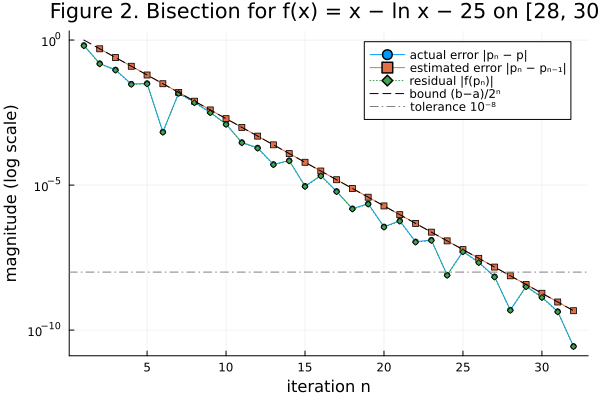

In [9]:
n_bis = 1:length(ps_bis)
plot(n_bis, err_bis, yaxis=:log10, marker=:circle, ms=3, label="actual error |pₙ − p|")
plot!(n_bis, est_bis, marker=:square, ms=3, label="estimated error |pₙ − pₙ₋₁|")
plot!(n_bis, res_bis, marker=:diamond, ms=3, linestyle=:dot, label="residual |f(pₙ)|")
plot!(n_bis, 2 ./ 2.0 .^ n_bis, linestyle=:dash, color=:black, label="bound (b−a)/2ⁿ")
hline!([1e-8], color=:gray, linestyle=:dashdot, label="tolerance 10⁻⁸")
xlabel!("iteration n")
ylabel!("magnitude (log scale)")
title!("Figure 2. Bisection for f(x) = x − ln x − 25 on [28, 30]")

*Figure 2. Bisection on $[28,30]$: actual error, estimated error $|p_n-p_{n-1}|$, and residual $|f(p_n)|$ at each iteration (log scale). The estimated error lies exactly on the bound $(b-a)/2^n$. The actual error and the residual zig-zag below it and nearly coincide.*

**Analysis.**

* **Which is which?** $|p_n-p|$ is the **actual error**. We can only compute it because we were given $p$. $|p_n-p_{n-1}|$ is an **estimated error**. $|f(p_n)|$ is the **residual**.
* **How they compare.** The estimated error is the smooth geometric sequence $2/2^n$. It lies exactly on the theoretical bound, and always above the actual error, because for bisection $|p_n-p|\le |p_n-p_{n-1}|$. The actual error is erratic. For example, $p_6 = 28.34375$ happens to be within $7\times10^{-4}$ of $p$, but the error at $n=7$ is twenty times larger. The residual follows the actual error almost exactly, scaled by $|f'(p)|\approx0.965$, because $f(p_n) = f'(\xi)(p_n-p)$ by the mean value theorem.
* **Practical stopping criteria.** If $p$ is unknown, only $|p_n-p_{n-1}|$ (equivalently, the bracket half-width) and $|f(p_n)|$ can be computed. For bisection the width test is the safer one, because it is a *guaranteed* bound on the error. A small residual implies a small error only when $|f'|$ is not small near $p$, which happens to be true here.
* **First iteration below $10^{-8}$.** Actual error: $n=24$. Residual: $n=24$. Estimated error: $n=28$. So they do *not* occur at the same iteration. The estimated error reaches the tolerance exactly at the 28th midpoint (27 bisections), matching part (a), because it *is* the bound. The actual error got there 4 steps earlier by luck, and it actually goes back above $10^{-8}$ at $n=25,26$. That is why (a) gives the iteration count that *guarantees* the tolerance, not the first time it is reached.

## 1(d) Newton's method from $p_0 = 29$

**Prediction.** From (b), about 2 iterations for an actual error below $10^{-8}$, with the number of correct digits roughly doubling and $\alpha\approx 2$. The estimated error $|p_n-p_{n-1}|$ should lag one step behind: once $p_n$ is much more accurate than $p_{n-1}$, $|p_n-p_{n-1}|\approx |p_{n-1}-p|$. So it should drop below $10^{-8}$ at $n=3$.

**Implementation.** This follows `newton_method` from class (Oct 8), but stores every iterate $p_0, p_1, \dots$. It stops when the step is $\le\delta$ (default: exactly zero, so we see the whole run) or when an iterate is not finite.

In [10]:
function newton_history(f, df, p0; nmax=50, δ=0.0)
    ps = [float(p0)]
    for n in 1:nmax
        x = ps[end];
        x_new = x - f(x) / df(x);
        push!(ps, x_new)
        if !isfinite(x_new) || abs(x_new - x) <= δ
            break
        end
    end
    return ps
end

newton_history (generic function with 1 method)

**Experiment.**

In [11]:
ps_newt = newton_history(f1, df1, 29.0)
print_root_table(ps_newt, f1, p_ref; nstart=0)

err_n = abs.(ps_newt .- p_ref);
est_n = [NaN; abs.(diff(ps_newt))];
res_n = abs.(f1.(ps_newt));
println()
println("First n with |p_n - p|       < 1e-8 : ", first_below(err_n, 1e-8; nstart=0))
println("First n with |p_n - p_{n-1}| < 1e-8 : ", first_below(est_n, 1e-8; nstart=0))
println("First n with |f(p_n)|        < 1e-8 : ", first_below(res_n, 1e-8; nstart=0))

Iteration                     p_n     |p_n - p|   |p_n - p_{n-1}|      |f(p_n)|
        0                      29    6.5557e-01                 —    6.3270e-01
        1      28.344699252485992    2.6869e-04        6.5530e-01    2.5922e-04
        2      28.344430557936434    4.6207e-11        2.6869e-04    4.4928e-11
        3      28.344430557889865    3.6238e-13        4.6569e-11    3.5527e-15
        4      28.344430557889861    3.6593e-13        3.5527e-15    0.0000e+00
        5      28.344430557889861    3.6593e-13        0.0000e+00    0.0000e+00

First n with |p_n - p|       < 1e-8 : 2
First n with |p_n - p_{n-1}| < 1e-8 : 3
First n with |f(p_n)|        < 1e-8 : 2


**Something unexpected.** The actual error $|p_n-p|$ stops decreasing at about $3.7\times10^{-13}$, while the residual and the step size reach $0$. Double precision near 28 has spacing $\approx 3.6\times10^{-15}$, so a floor at $10^{-13}$ is suspicious. One possibility is that the **reference value itself** is slightly off. To check this *independently of Newton*, we run bisection in 256-bit `BigFloat` arithmetic (about 77 digits) on $[28,30]$.

In [12]:
setprecision(BigFloat, 256)
p_big = bisection_history(f1, big"28.0", big"30.0"; nmax=250)[end]   # independent high-precision root
println("High-precision root p*  = ", p_big)
println("p* rounded to Float64   = ", Float64(p_big))
println("Given reference value   = ", p_ref)
@printf("p_ref - p*              = %.4e\n", Float64(big(p_ref) - p_big))
@printf("Float64 spacing near 28 = %.4e\n", eps(28.0))

High-precision root p*  = 28.3444305578898612489009000639159343517595388328511519633109316064291410834679


p* rounded to Float64   = 28.34443055788986
Given reference value   = 28.344430557890227
p_ref - p*              = 3.6611e-13
Float64 spacing near 28 = 3.5527e-15


So the given reference value is accurate only to about $3.7\times10^{-13}$, and Newton's final iterate is the true root rounded to double precision. **This does not affect any of the $10^{-8}$ comparisons.** It does matter for checking the convergence order, which needs errors far below $10^{-13}$. So below we measure the errors against the high-precision root $p^*$.

In [13]:
e_big = [abs(big(pn) - p_big) for pn in ps_newt]      # errors vs high-precision root
@printf("%3s  %14s  %10s  %20s  %18s\n", "n", "|p_n - p*|", "digits", "|e_n|/|e_{n-1}|^2", "α estimate")
for k in eachindex(ps_newt)
    e = e_big[k]
    ratio = k == 1 ? "—" : @sprintf("%.4e", Float64(e / e_big[k-1]^2))
    α = k <= 2 ? "—" : @sprintf("%.4f", Float64((log(e) - log(e_big[k-1])) / (log(e_big[k-1]) - log(e_big[k-2]))))
    @printf("%3d  %14.4e  %10.2f  %20s  %18s\n", k - 1, Float64(e), Float64(-log10(e)), ratio, α)
end
@printf("\nPredicted C = 1/(2p(p-1)) = %.4e\n", 1 / (2 * p_ref * (p_ref - 1)))

  n      |p_n - p*|      digits     |e_n|/|e_{n-1}|^2          α estimate
  0      6.5557e-01        0.18                     —                   —


  1      2.6869e-04        3.57            6.2520e-04                   —
  2      4.6573e-11       10.33            6.4508e-04              1.9960
  3      3.7367e-15       14.43            1.7227e+06              0.6058
  4      1.8394e-16       15.74            1.3174e+13              0.3193
  5      1.8394e-16       15.74            5.4366e+15             -0.0000

Predicted C = 1/(2p(p-1)) = 6.4511e-04


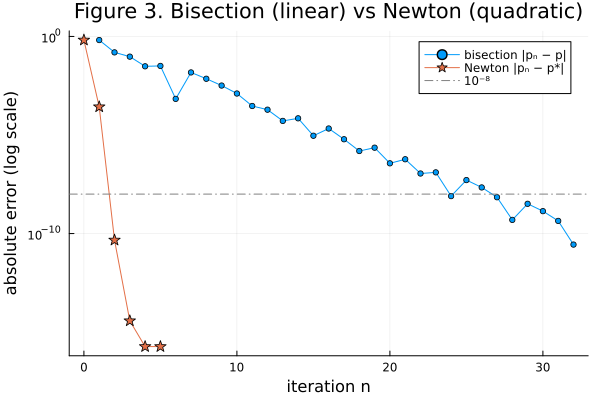

In [14]:
n_newt = 0:length(ps_newt)-1
clean(v) = [x == 0 ? NaN : x for x in v]       # zeros can't be drawn on a log scale
plot(n_bis, err_bis, yaxis=:log10, marker=:circle, ms=3, label="bisection |pₙ − p|")
plot!(n_newt, clean(Float64.(e_big)), marker=:star5, ms=6, label="Newton |pₙ − p*|")
hline!([1e-8], color=:gray, linestyle=:dashdot, label="10⁻⁸")
xlabel!("iteration n")
ylabel!("absolute error (log scale)")
title!("Figure 3. Bisection (linear) vs Newton (quadratic)")

*Figure 3. Absolute error vs. iteration for bisection (circles) and Newton from $p_0=29$ (stars), log scale. Bisection gains about one binary digit per step. Newton's error falls below $10^{-8}$ at $n=2$ and reaches rounding level by $n=3$–$4$. Newton errors are measured against the high-precision root $p^*$.*

**Analysis.**
* The number of correct digits goes roughly $0.2 \to 3.6 \to 10.3 \to$ machine precision. Each step more than doubles it, as predicted in (b).
* The order estimate from the formula in (b) gives $\alpha \approx 2.0$ for the only usable triple $(e_0,e_1,e_2)$. Later errors are at rounding level, so their $\alpha$ values mean nothing. The ratio $|e_n|/|e_{n-1}|^2$ is $\approx 6.3\times10^{-4}$ and then $\approx 6.45\times10^{-4}$, matching the predicted $C$.
* **First iterations below $10^{-8}$:** actual error and residual at $n=2$, estimated error at $n=3$. As predicted, the step test lags by one iteration, because $|p_3-p_2|$ measures the error of $p_2$. With quadratic convergence this makes the step test conservative: when it stops, the true error is far below the tolerance.
* **Consistent with (b)?** Yes. The error went $0.66 \to 2.7\times10^{-4} \to 4.7\times10^{-11}$, which is the quadratic reduction $|e_{n+1}|\approx C|e_n|^2$ predicted in (b).
* **Bisection vs Newton:** 28 (guaranteed) or 24 (actual) bisection iterations vs 2 Newton iterations. But Newton needs $f'$, and only converges locally, as part (e) shows.

## 1(e) Newton's method from $p_0 = 1.0000000001$

**Prediction (before running).** Write $p_0 = 1+h$ with $h=10^{-10}$. Since $x=1$ is the minimum of $f$:
$$
f(p_0) \approx -24, \qquad f'(p_0) = 1-\frac{1}{1+h} = \frac{h}{1+h}\approx 10^{-10}.
$$
The tangent line is almost horizontal, so the first step is enormous:
$$
p_1 = p_0 - \frac{f(p_0)}{f'(p_0)} \approx 1 + \frac{24}{10^{-10}} \approx 2.4\times10^{11}.
$$
Because $f'(p_0)>0$, the jump is to the *right*, toward the **larger** root, even though $p_0$ is much closer in distance to the tiny root near $10^{-11}$. For large $x$ the Newton map simplifies:
$$
p_{n+1} = p_n - \frac{p_n - \ln p_n - 25}{1-1/p_n} = \frac{p_n(\ln p_n + 24)}{p_n - 1} \approx \ln p_n + 24,
$$
so $p_2\approx \ln(2.4\times10^{11})+24\approx 50.2$. That is a huge jump out and then a quick return. Since $f$ is convex and increasing for $x>p$, the later iterates stay to the right of $p$ and decrease monotonically to it. We expect convergence to $28.344\ldots$ in a handful of steps.

**Implementation.** We reuse `newton_history` from 1(d), unchanged, first with $p_0=1.0000000001$ and then with $p_0=1$.

**Experiment.**

In [15]:
ps_e = newton_history(f1, df1, 1.0000000001)
print_root_table(ps_e, f1, p_ref; nstart=0)

Iteration                     p_n     |p_n - p|   |p_n - p_{n-1}|      |f(p_n)|
        0            1.0000000001    2.7344e+01                 —    2.4000e+01
        1      239999980143.31259    2.4000e+11        2.4000e+11    2.4000e+11
        2       50.20391845703125    2.1859e+01        2.4000e+11    2.1288e+01
        3       28.48344816032175    1.3902e-01        2.1720e+01    1.3413e-01
        4      28.344442941913812    1.2384e-05        1.3901e-01    1.1947e-05
        5      28.344430557889961    2.6645e-13        1.2384e-05    9.5923e-14
        6      28.344430557889861    3.6593e-13        9.9476e-14    0.0000e+00
        7      28.344430557889861    3.6593e-13        0.0000e+00    0.0000e+00


In [16]:
# p0 = 1 exactly
p0 = 1.0
@show f1(p0);
@show df1(p0);
p1 = p0 - f1(p0)/df1(p0);
@show p1;
@show f1(p1);              # Inf - log(Inf) = Inf - Inf = NaN
p2 = p1 - f1(p1)/df1(p1);
@show p2;

f1(p0) = -24.0
df1(p0) = 0.0
p1 = Inf
f1(p1) = NaN
p2 = NaN


**Analysis.**
* The output matches the prediction: $p_1\approx2.4\times10^{11}$, $p_2\approx50.2$, then fast convergence. The error is below $10^{-8}$ by $n=5$, and Newton converges to the **larger** root, not the nearby tiny one.
* **Why.** Each Newton step is $-f(p_n)/f'(p_n)$. Near a critical point of $f$ (here the minimum at $x=1$), $f'$ is tiny but $f$ is not, so the step is huge. The convergence theorem only promises convergence for $p_0$ "sufficiently close" to a *simple* root, and $1+10^{-10}$ is not close to either root in that sense. We got lucky: $f$ is convex and grows only like $x$ for large $x$, so the run recovers quickly. For many functions such a jump would land somewhere useless.
* **Floating point.** $p_1$ comes out as $2.3999998\times10^{11}$, not $2.4000000\times10^{11}$. The reason is that $1.0000000001$ is not exactly representable: the stored value is $1+1.0000000827\times10^{-10}$, and $24/(1.0000000827\times10^{-10}) \approx 2.3999998\times10^{11}$. See part (f). Newton corrects itself afterwards either way.
* **$p_0=1$ exactly:** $f'(1)=0$, so the first step divides $-24$ by $0$. In IEEE arithmetic that gives $p_1=+\infty$. Then $f(\infty)=\infty-\infty=\text{NaN}$, so $p_2 = \text{NaN}$, and every later iterate is NaN. Geometrically, the tangent line at the minimum is horizontal and never meets the $x$-axis.

## 1(f) Verifying an AI claim

**Claim 1 (from Claude):** "For $p_0 = 1+10^{-10}$, the first Newton iterate is $p_1\approx 1+24/10^{-10} = 2.4\times10^{11}$."

**Verification.** I re-derived the step by hand (in 1(e)), then recomputed $p_1$ in 256-bit `BigFloat` from the *same* stored `Float64` value of $p_0$:

In [17]:
p0 = 1.0000000001
p1_f64 = p0 - f1(p0)/df1(p0)                       # double precision
p1_big = big(p0) - f1(big(p0))/df1(big(p0))        # 256-bit
@printf("stored h = p0 - 1     = %.17e\n", Float64(big(p0) - 1))
@printf("p1 (Float64)          = %.10e\n", p1_f64)
@printf("p1 (BigFloat)         = %.10e\n", Float64(p1_big))
@printf("1 + 24/1e-10          = %.10e\n", 1 + 24/1e-10)
@printf("relative error of Float64 p1 = %.2e\n", Float64(abs(p1_f64 - p1_big)/p1_big))

stored h = p0 - 1     = 1.00000008274037100e-10
p1 (Float64)          = 2.3999998014e+11
p1 (BigFloat)         = 2.3999998017e+11
1 + 24/1e-10          = 2.4000000000e+11
relative error of Float64 p1 = 1.00e-10


The claim $p_1\approx2.4\times10^{11}$ is right to the leading digits. **But the AI's explanation of the small discrepancy was wrong.** It said that $p_1 = 2.3999998\times10^{11}$ (instead of $2.4000000\times10^{11}$) was caused by catastrophic cancellation in $f'(p_0) = 1-1/p_0$, leaving only 6–7 correct digits. The `BigFloat` check disproves that: computed from the same stored $p_0$, the `Float64` value of $p_1$ has relative error $\approx10^{-10}$, so about 10 correct digits. The real cause is representation error in the input. $p_0$ is stored as $1 + 1.0000000827\times10^{-10}$, and $24/(1.0000000827\times10^{-10}) = 2.3999998\times10^{11}$ exactly accounts for the difference. (Cancellation *could* cost up to about $\varepsilon/h\approx10^{-6}$ relative accuracy in $f'(p_0)$, but here the rounding happened to be much more favorable.) I corrected the explanation in 1(e).

**Claim 2 / a weakness I found:** the AI's first version of the convergence check in 1(d) treated the given $p = 28.344430557890227$ as exact. With it, the errors stopped decreasing at $3.7\times10^{-13}$, about 100 times above double-precision spacing near 28. The ratio $|e_3|/|e_2|^2$ came out as about $1.7\times10^{8}$, which looks like a breakdown of quadratic convergence. To check, I computed the root **independently with bisection in `BigFloat`**. This uses only sign changes, not Newton. The given value is off by $3.66\times10^{-13}$. I corrected 1(d) to measure errors against the high-precision root. The errors then keep decreasing down to $\sim10^{-16}$, and the ratios at $n=1,2$ match $C\approx6.45\times10^{-4}$ and $\alpha\approx2$. After $n=2$ the error is at rounding level, so ratios computed from it carry no information either way.

---
# Problem 2 — Polynomial Roots

$$
f(x) = 230x^4 + 18x^3 + 9x^2 - 221x - 9, \qquad
f'(x) = 920x^3 + 54x^2 + 18x - 221, \qquad
f''(x) = 2760x^2 + 108x + 18 .
$$

The discriminant of $f''$ is $108^2 - 4(2760)(18) = 11664 - 198720 < 0$, so $f''(x)>0$ for all real $x$. **$f$ is strictly convex**, so $f'$ is strictly increasing and has **exactly one** real zero $x_c$ (the minimum of $f$). This explains most of what follows.

In [18]:
f2(x) = 230x^4 + 18x^3 + 9x^2 - 221x - 9;
df2(x) = 920x^3 + 54x^2 + 18x - 221;

## 2(a) Plot and initial guesses

**Prediction.** $f$ is convex (shown above), so on $[-1,1]$ its graph should be U-shaped, with a single minimum and exactly two crossings of the $x$-axis: one in $[-1,0]$ and one in $[0,1]$. Since $f(0)=-9$ is small compared to the size of the coefficients, the left root should be close to $0$.

**Implementation / Experiment.** Plot $f$ on $[-1,1]$, plus zoomed panels near each root.

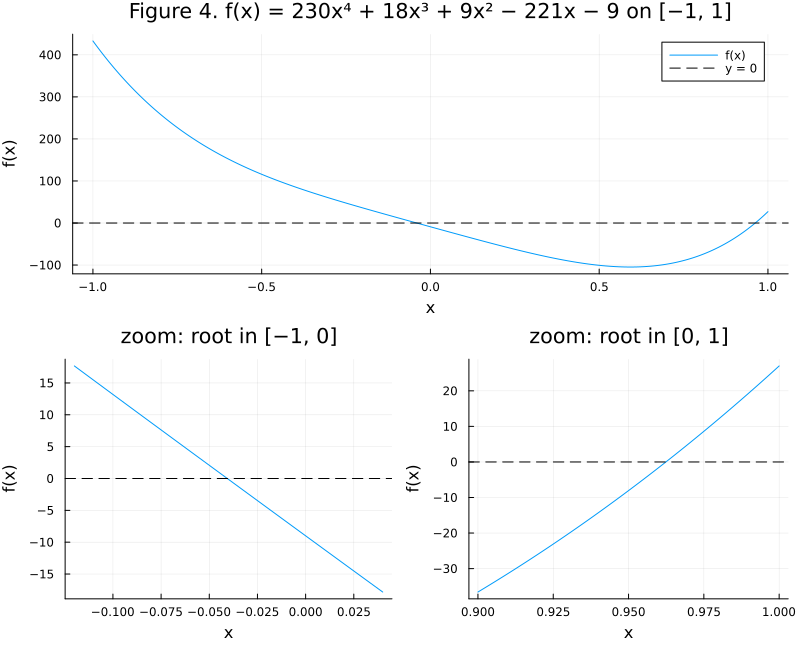

In [19]:
xx = LinRange(-1, 1, 2000)
pA = plot(xx, f2.(xx), label="f(x)", xlabel="x", ylabel="f(x)",
          title="Figure 4. f(x) = 230x⁴ + 18x³ + 9x² − 221x − 9 on [−1, 1]")
hline!(pA, [0], color=:black, linestyle=:dash, label="y = 0")

xl = LinRange(-0.12, 0.04, 400)
pB = plot(xl, f2.(xl), label="", xlabel="x", ylabel="f(x)", title="zoom: root in [−1, 0]")
hline!(pB, [0], color=:black, linestyle=:dash, label="")

xr = LinRange(0.9, 1.0, 400)
pC = plot(xr, f2.(xr), label="", xlabel="x", ylabel="f(x)", title="zoom: root in [0, 1]")
hline!(pC, [0], color=:black, linestyle=:dash, label="")

plot(pA, pB, pC, layout=@layout([a; b c]), size=(800, 650))

*Figure 4. $f$ on $[-1,1]$ (top) with zooms near the two real roots (bottom). $f$ is U-shaped (convex) and crosses zero near $x\approx-0.04$ and $x\approx0.96$.*

**Analysis.** From the zoomed plots, the roots are near $x\approx-0.04$ and $x\approx0.96$. Initial guesses:
$$
p_0 = -0.05 \quad\text{and}\quad p_0 = 1.0 .
$$

**Prediction for Newton (tested in 2(b)).** $p_0=-0.05$ should converge to the left root and $p_0=1.0$ to the right root. Reasons:
* Each guess is close to a root, and $|f'|$ is large there ($f'(-0.05)\approx-222$, $f'(1)=771$), so the tangent line crosses the axis near that root.
* The only critical point $x_c$ is the minimum, between the two roots (around $x\approx0.6$ in the plot). Because $f$ is convex, a guess left of $x_c$ (where $f'<0$) moves toward the left root, and a guess right of $x_c$ moves toward the right root. Neither guess is near $x_c$, so neither should get a wild first step.

## 2(b) Newton's method for the two real roots

**Stopping criterion:** stop at the first $n$ with $|p_n-p_{n-1}|<10^{-8}$ (estimated error).

**Prediction.** From 2(a), each guess should converge to its nearby root. Both roots are simple ($f'\ne0$ there), so convergence should be quadratic and take only a few iterations.

**Implementation.** This is the class `newton_method`, modified to use only the step-size test and to return `(root, iterations)`. That is also the version 2(d) asks for. `verbose=false` silences warnings during the large sweeps.

In [20]:
function newton_method(f, df, x0; nmax=100, δ=1e-8, verbose=true)
    x = x0;
    for n in 1:nmax
        x_new = x - f(x) / df(x);
        if !isfinite(x_new)              # e.g. division by f'(x) = 0
            verbose && @warn("Newton broke down (non-finite iterate) at n = $n")
            return x_new, n
        end
        if abs(x_new - x) < δ            # |p_n - p_{n-1}| < δ
            return x_new, n
        end
        x = x_new;
    end
    verbose && @error("Newton did not converge after $nmax iterations")
    return x, nmax
end

newton_method (generic function with 1 method)

**Experiment.**

In [21]:
for p0 in (-0.05, 1.0)
    println("p0 = $p0")
    print_root_table(newton_history(f2, df2, p0; δ=1e-8), f2, NaN; nstart=0)
    println()
end

p0 = -0.05
Iteration                     p_n     |p_n - p|   |p_n - p_{n-1}|      |f(p_n)|
        0   -0.050000000000000003           NaN                 —    2.0717e+00
        1   -0.040663027312060569           NaN        9.3370e-03    8.2895e-04
        2   -0.040659288316331789           NaN        3.7390e-06    1.2702e-10
        3   -0.040659288315758865           NaN        5.7292e-13    1.7764e-15

p0 = 1.0
Iteration                     p_n     |p_n - p|   |p_n - p_{n-1}|      |f(p_n)|
        0                       1           NaN                 —    2.7000e+01
        1     0.96498054474708173           NaN        3.5019e-02    1.7297e+00
        2     0.96241172497925997           NaN        2.5688e-03    8.8677e-03
        3     0.96239841910631863           NaN        1.3306e-05    2.3709e-07
        4     0.96239841875054144           NaN        3.5578e-10    0.0000e+00



(The $|p_n-p|$ column is `NaN` because there is no reference root here. The estimated error is the column we use.)

In [22]:
@printf("%8s  %20s  %10s  %12s\n", "p0", "root p", "iterations", "|f(p)|")
for p0 in (-0.05, 1.0)
    r, n = newton_method(f2, df2, p0)
    @printf("%8.3f  %20.15f  %10d  %12.3e\n", p0, r, n, abs(f2(r)))
end

      p0                root p  iterations        |f(p)|
  -0.050    -0.040659288315759           3     1.776e-15


   1.000     0.962398418750541           4     0.000e+00


**Analysis.** Both guesses converged to the predicted root: $-0.040659288315759$ and $0.962398418750541$, in only a few iterations, with residuals at rounding level. The step sizes shrink quadratically, as expected for simple roots ($f'\ne0$ at both).

## 2(c) Complex initial guesses

**Prediction (how I found a good guess).** Call the roots $r_1, r_2$ (real, from 2(b)) and $z,\bar z$ (complex pair). Vieta's formulas give
$$
r_1 + r_2 + 2\,\mathrm{Re}(z) = -\frac{18}{230}, \qquad r_1 r_2 |z|^2 = -\frac{9}{230}.
$$
With $r_1\approx-0.04066$ and $r_2\approx0.96240$ this gives $\mathrm{Re}(z)\approx-0.500$ and $|z|\approx1.000$, so $z\approx-0.5\pm0.87i$. So I tried $p_0=-0.5+0.8i$, and I expect it to converge to $z$. Guesses near the real axis may instead be pulled to a real root.

(In fact $f(x) = (x^2+x+1)(230x^2-212x-9)$ exactly, see 2(f), so the nonreal roots are $-\tfrac12\pm\tfrac{\sqrt3}{2}i$.)

**Implementation.** Newton's method needs no changes for complex numbers, because Julia's arithmetic and `abs` work on complex values. We reuse `newton_method` from 2(b) with complex $p_0$.

**Experiment.**

In [23]:
z_exact = -1/2 + sqrt(3)/2*im
roots_all = [(212 - sqrt(53224))/460, (212 + sqrt(53224))/460, z_exact, conj(z_exact)]
root_names = ["r₁ ≈ -0.0407", "r₂ ≈ 0.9624", "z = -1/2 + (√3/2)i", "z̄ = -1/2 - (√3/2)i"]

nearest_root(z) = isfinite(z) ? argmin(abs.(z .- roots_all)) : 0

@printf("%14s   %40s  %5s   %s\n", "p0", "limit", "iters", "which root")
for p0 in (-0.5 + 0.8im, -0.5 - 0.8im, -1.0 + 1.0im, 2.0im, 1.0im, 0.5 + 0.5im, 0.1 + 0.3im, -2.0 - 0.5im, 1.0 + 1.0im)
    r, n = newton_method(f2, df2, p0)
    k = nearest_root(r)
    @printf("%14s   %40s  %5d   %s\n", string(p0), string(round(r, digits=12)), n, k == 0 ? "none" : root_names[k])
end

            p0                                      limit  iters   which root
  -0.5 + 0.8im                    -0.5 + 0.866025403784im      5   z = -1/2 + (√3/2)i


  -0.5 - 0.8im                    -0.5 - 0.866025403784im      5   z̄ = -1/2 - (√3/2)i
  -1.0 + 1.0im                    -0.5 + 0.866025403784im      7   z = -1/2 + (√3/2)i
   0.0 + 2.0im                    -0.5 + 0.866025403784im     10   z = -1/2 + (√3/2)i
   0.0 + 1.0im                    -0.040659288316 - 0.0im      8   r₁ ≈ -0.0407
   0.5 + 0.5im                    -0.040659288316 - 0.0im      5   r₁ ≈ -0.0407
   0.1 + 0.3im                    -0.040659288316 + 0.0im      4   r₁ ≈ -0.0407
  -2.0 - 0.5im                    -0.040659288316 + 0.0im      8   r₁ ≈ -0.0407
   1.0 + 1.0im                    -0.040659288316 + 0.0im      7   r₁ ≈ -0.0407


The basin-of-attraction picture below works like the Newton fractal for $z^3-1$ from class (Oct 15). Each starting point is colored by the root Newton converges to.

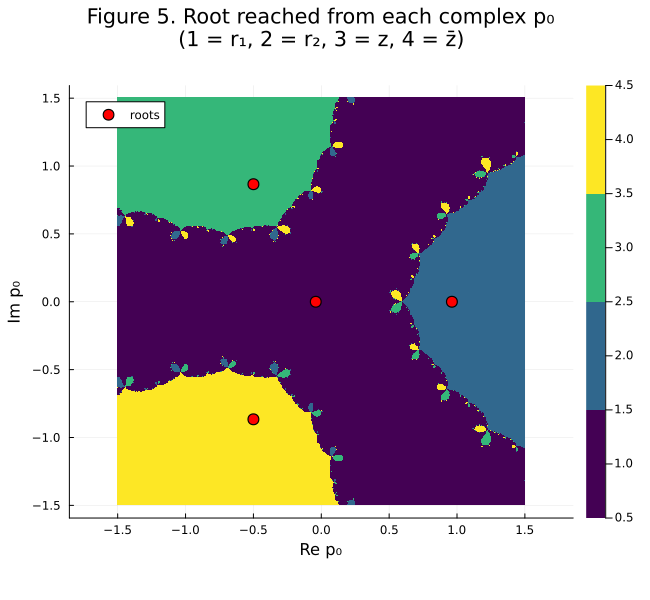

In [24]:
xs = LinRange(-1.5, 1.5, 500)
ys = LinRange(-1.5, 1.5, 500)
basin = [nearest_root(first(newton_method(f2, df2, x + im*y; verbose=false))) for y in ys, x in xs]
heatmap(xs, ys, basin, aspect_ratio=:equal, color=cgrad(:viridis, 4, categorical=true), clims=(0.5, 4.5),
        xlabel="Re p₀", ylabel="Im p₀", size=(650, 600),
        title="Figure 5. Root reached from each complex p₀\n(1 = r₁, 2 = r₂, 3 = z, 4 = z̄)")
scatter!(real.(roots_all), imag.(roots_all), color=:red, ms=6, label="roots")

*Figure 5. Basins of attraction of Newton's method for complex $p_0\in[-1.5,1.5]\times[-1.5,1.5]$. Color shows which of the four roots (red dots) the iteration reaches. The picture is symmetric about the real axis, and the basin boundaries are fractal.*

**Analysis.**
* $p_0=-0.5+0.8i$ converged to $-0.5+0.866025403784439i=-\tfrac12+\tfrac{\sqrt3}{2}i$. The conjugate guess converged to the conjugate root.
* **Not all complex guesses go to the same root.** $-1+i$ and $2i$ went to $z$, and $-0.5-0.8i$ went to $\bar z$. But many complex guesses ($0.5+0.5i$, $0.1+0.3i$, $i$, $1+i$, and even $-2-0.5i$) converged to the *real* root $r_1$: their imaginary parts shrank to zero. Figure 5 shows that the basins have intricate, fractal boundaries, as in the $z^3-1$ example from class.
* **Symmetry.** $f$ has real coefficients, so $\overline{N(p)}=N(\bar p)$ for the Newton map $N(p)=p-f(p)/f'(p)$. The picture is therefore symmetric across the real axis, and conjugate starting points go to conjugate roots.
* **A real initial guess cannot converge to a nonreal root.** If $p_n$ is real, then $f(p_n)$ and $f'(p_n)$ are real, so $p_{n+1}$ is real (unless $f'(p_n)=0$ and the method breaks down). By induction every iterate is real, so any limit is real.

## 2(d) Iteration count as a function of $p_0\in[0,1]$

**Prediction.** By convexity, every $p_0<x_c$ should go to $r_1$ and every $p_0>x_c$ to $r_2$. Starting points near a root should need few iterations. Starting points near $x_c\approx0.6$ (where $f'\approx0$) should take a huge first step and need many more.

**Implementation.** We reuse `newton_method` from 2(b), which returns only `(root, iterations)`.

**Experiment.**

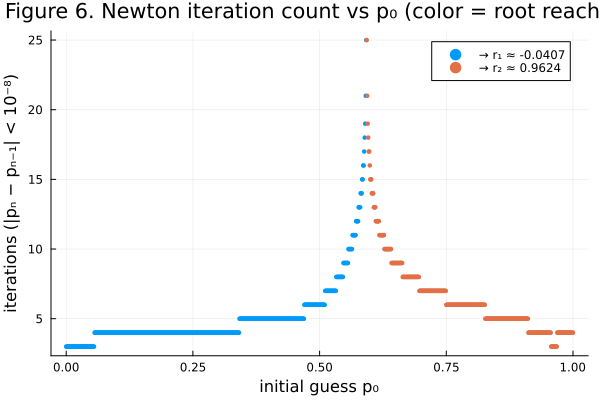

In [25]:
p0_vals = 0:0.001:1
results = [newton_method(f2, df2, p0; verbose=false) for p0 in p0_vals]
roots_found = first.(results)
iters = last.(results)
dest = [r < 0.5 ? "→ r₁ ≈ -0.0407" : "→ r₂ ≈ 0.9624" for r in roots_found]

scatter(p0_vals, iters, group=dest, ms=2.5, msw=0,
        xlabel="initial guess p₀", ylabel="iterations (|pₙ − pₙ₋₁| < 10⁻⁸)",
        title="Figure 6. Newton iteration count vs p₀ (color = root reached)")

*Figure 6. Number of Newton iterations needed to reach $|p_n-p_{n-1}|<10^{-8}$ for each $p_0$ in `0:0.001:1`, colored by the root reached. Most starting points need only a few iterations (median 5). The sharp spike near $p_0\approx0.59$ reaches 25 iterations.*

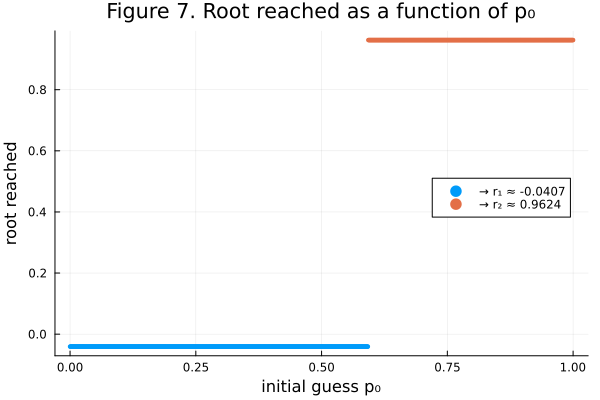

In [26]:
scatter(p0_vals, roots_found, group=dest, ms=2.5, msw=0, legend=:right,
        xlabel="initial guess p₀", ylabel="root reached",
        title="Figure 7. Root reached as a function of p₀")

*Figure 7. Root reached as a function of $p_0$. Every $p_0\le0.592$ converges to $r_1\approx-0.0407$ and every $p_0\ge0.593$ to $r_2\approx0.9624$.*

In [27]:
i_max = argmax(iters)
println("Starting points converging to r1: ", count(<(0.5), roots_found),
        ",  to r2: ", count(>(0.5), roots_found), ",  failures: ", count(!isfinite, roots_found))
println("Last p0 going to r1: ", p0_vals[findlast(<(0.5), roots_found)],
        "   first p0 going to r2: ", p0_vals[findfirst(>(0.5), roots_found)])
println("Maximum iterations: ", iters[i_max], " at p0 = ", p0_vals[i_max])
println("Median iterations: ", sort(iters)[div(end, 2)])
println("Iterations for p0 in [0, 0.1] and [0.9, 1]: ", extrema(iters[1:101]), "  ", extrema(iters[901:1001]))
println("\nNewton iterates starting from p0 = 0.593:")
ps593 = newton_history(f2, df2, 0.593; δ=1e-8)
print_root_table(ps593[1:min(10, end)], f2, NaN; nstart=0)

Starting points converging to r1: 593

,  to r2: 408,  failures: 0
Last p0 going to r1: 0.592   first p0 going to r2: 0.593
Maximum iterations: 25 at p0 = 0.592
Median iterations: 5
Iterations for p0 in [0, 0.1] and [0.9, 1]: (3, 4)  (3, 5)

Newton iterates starting from p0 = 0.593:
Iteration                     p_n     |p_n - p|   |p_n - p_{n-1}|      |f(p_n)|


        0     0.59299999999999997           NaN                 —    1.0469e+02
        1      206.40940225086095           NaN        2.0582e+02    4.1765e+11
        2      154.80214231468406           NaN        5.1607e+01    1.3215e+11
        3      116.09669322205906           NaN        3.8705e+01    4.1812e+10
        4      87.067602346492777           NaN        2.9029e+01    1.3230e+10
        5      65.295781385835653           NaN        2.1772e+01    4.1859e+09
        6      48.966916557446581           NaN        1.6329e+01    1.3245e+09
        7      36.720277360779129           NaN        1.2247e+01    4.1906e+08
        8      27.535325176089952           NaN        9.1850e+00    1.3259e+08
        9       20.64667337468741           NaN        6.8887e+00    4.1953e+07


**Analysis.**
* The interval splits **cleanly**: every $p_0\in[0,0.592]$ converges to $r_1$ and every $p_0\in[0.593,1]$ to $r_2$. Because $f$ is convex there is no fractal mixing on the real line. The complicated boundaries only appear in the complex plane (Figure 5).
* Starting points near a root ($p_0\in[0,0.1]$ or $[0.9,1]$) need only 3–5 iterations, and the median over the whole sweep is 5.
* The **slowest** starting points form a sharp spike at $p_0\approx0.59$, peaking at 25 iterations at $p_0=0.592$ and $0.593$. The trace from $p_0=0.593$ shows why: $f'(0.593)$ is tiny, so $p_1$ is thrown far out to $p_1\approx 206$. From that far away, Newton on a quartic acts like Newton on $230x^4$, which only multiplies $x$ by about $3/4$ per step (linear, not quadratic). Most of the iterations are spent walking back before quadratic convergence starts.
* The iteration count rises smoothly toward the spike from both sides, because the first jump grows like $1/|f'(p_0)|\sim1/|p_0-x_c|$.

## 2(e) $f'(x)$ on $[0,1]$

**Prediction.** Since $f''>0$, $f'$ is increasing, and $f'(0)=-221<0<771=f'(1)$, so $f'$ has exactly one zero in $[0,1]$. It should sit exactly at the spike in Figure 6 and at the switch between basins in Figure 7.

**Implementation.** Find the zero of $f'$ with `bisection_history` from 1(c), then plot $f'$ under the iteration-count plot with a shared $x$-axis.

**Experiment.**

f'(x) = 0 at x_c = 0.592516367005939   (f'(x_c) = -5.684341886080802e-14,  f(x_c) = -104.69366613177823)


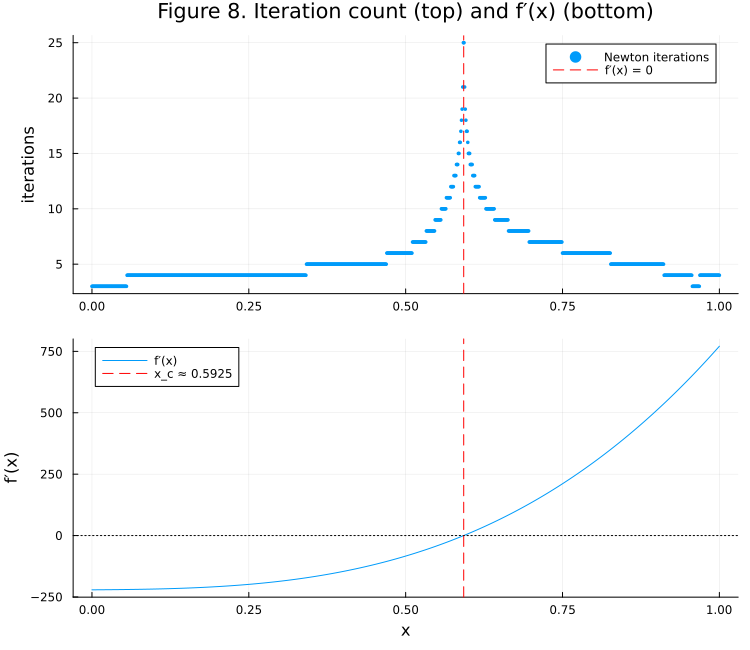

In [28]:
x_c = bisection_history(df2, 0.0, 1.0; nmax=60)[end]   # zero of f', using bisection from Problem 1
println("f'(x) = 0 at x_c = $x_c   (f'(x_c) = $(df2(x_c)),  f(x_c) = $(f2(x_c)))")

x01 = LinRange(0, 1, 1000)
pTop = scatter(p0_vals, iters, ms=2, msw=0, label="Newton iterations", ylabel="iterations",
               title="Figure 8. Iteration count (top) and f′(x) (bottom)")
vline!(pTop, [x_c], color=:red, linestyle=:dash, label="f′(x) = 0")
pBot = plot(x01, df2.(x01), label="f′(x)", xlabel="x", ylabel="f′(x)")
hline!(pBot, [0], color=:black, linestyle=:dot, label="")
vline!(pBot, [x_c], color=:red, linestyle=:dash, label="x_c ≈ $(round(x_c, digits=4))")
plot(pTop, pBot, layout=(2, 1), size=(750, 650), link=:x)

*Figure 8. Iteration count (top) and $f'(x)$ (bottom) on $[0,1]$, with a shared $x$-axis. The red dashed line marks the only zero of $f'$, $x_c\approx0.5925$. The spike in iteration count and the switch between basins are both exactly there.*

**Analysis.**
* $f'(x)=0$ at exactly one point of $[0,1]$: $x_c\approx0.592516$, the minimum of $f$. As shown at the start of Problem 2, it is the only real critical point.
* **Relationship:** the spike in the iteration count sits exactly at $x_c$, and the switch between the two basins (between $p_0=0.592$ and $0.593$) also happens exactly at $x_c$.
* **Why small $f'(p_n)$ causes trouble.** The Newton step is $-f(p_n)/f'(p_n)$. Near $x_c$ the numerator is not small ($f(x_c)\approx-104.7$) but the denominator is nearly zero, so the step is huge: a nearly horizontal tangent line meets the axis far away. That throws the iterate out of the region where $|e_{n+1}|\approx\left|\tfrac{f''}{2f'}\right|e_n^2$ applies (the constant blows up as $f'\to0$), and the method must walk back. The *sign* of $f'(p_0)$ decides which way the jump goes, which is why the basin boundary is exactly at $x_c$. At $x_c$ itself Newton divides by zero, just like $p_0=1$ in Problem 1(e).

## 2(f) Verifying an AI claim

**Claim (from Claude):** "$f(x)=(x^2+x+1)(230x^2-212x-9)$. So the nonreal roots are exactly $-\tfrac12\pm\tfrac{\sqrt3}{2}i$, and the real roots are $\dfrac{212\pm\sqrt{53224}}{460}$."

**Verification 1, by hand.**
$$
(x^2+x+1)(230x^2-212x-9) = 230x^4 + (230-212)x^3 + (230-212-9)x^2 + (-212-9)x - 9 = 230x^4+18x^3+9x^2-221x-9 \;\checkmark
$$
The quadratic formula on $230x^2-212x-9$: $x=\dfrac{212\pm\sqrt{212^2+4\cdot230\cdot9}}{460}=\dfrac{212\pm\sqrt{53224}}{460}$ ✓. The roots of $x^2+x+1$ are $\dfrac{-1\pm\sqrt{-3}}{2}$ ✓.

**Verification 2, numerically by a different method.** The roots of a polynomial are the eigenvalues of its companion matrix, which uses neither Newton nor the factorization:

In [29]:
c = [230, 18, 9, -221, -9] ./ 230            # monic coefficients
Ccomp = [-c[2] -c[3] -c[4] -c[5];
          1     0     0     0;
          0     1     0     0;
          0     0     1     0]
println("Companion-matrix eigenvalues:")
for λ in eigvals(Ccomp)
    println("   ", λ)
end
println("Closed-form roots from the factorization:")
for r in roots_all
    println("   ", r)
end
println("|Newton - closed form| for the real roots: ",
        abs(first(newton_method(f2, df2, -0.05)) - roots_all[1]), ",  ",
        abs(first(newton_method(f2, df2, 1.0)) - roots_all[2]))

Companion-matrix eigenvalues:


   -0.4999999999999996

 - 0.8660254037844378im
   -0.4999999999999996 + 0.8660254037844378im
   -0.04065928831575886 + 0.0im
   0.9623984187505414 + 0.0im
Closed-form roots from the factorization:
   -0.04065928831575885 + 0.0im
   0.9623984187505414 + 0.0im
   -0.5 + 0.8660254037844386im
   -0.5 - 0.8660254037844386im
|Newton - closed form| for the real roots: 1.3877787807814457e-17,  0.0


All three methods agree to about machine precision, so the claim is correct. I also checked a related AI statement, "$f$ is convex, so the basin boundary on $[0,1]$ is exactly at the zero of $f'$". The discriminant computation at the top of Problem 2 proves $f''>0$, and Figures 7–8 show the switch between $p_0=0.592$ and $0.593$, around $x_c=0.5925$.

---
# Problem 3 — Fixed-Point Iteration for $x^5 = 7$

We look for $p=7^{1/5}\approx1.4757731615945522$ using

$$
g_1(x) = x\left(1+\frac{7-x^5}{x^2}\right)^3, \qquad
g_2(x) = x - \frac{x^5-7}{x^2}, \qquad
g_3(x) = x - \frac{x^5-7}{5x^4}, \qquad
g_4(x) = x - \frac{x^5-7}{12}.
$$

(Formulas as given in the assignment.)

In [30]:
g1(x) = x * (1 + (7 - x^5)/x^2)^3;
g2(x) = x - (x^5 - 7)/x^2;
g3(x) = x - (x^5 - 7)/(5x^4);
g4(x) = x - (x^5 - 7)/12;
gs = [g1, g2, g3, g4];
p_fixed = 7^(1/5)

1.4757731615945522

## 3(a) Fixed points and local convergence

**Each $g_i$ fixes $p$.** At $x=p$ we have $p^5=7$, so $7-p^5=0$ and $p^5-7=0$. Hence
$g_1(p)=p(1+0)^3=p$, and $g_2(p)=g_3(p)=g_4(p)=p-0=p$.

**Derivatives at $p$.** We use $p^5=7$ repeatedly, in the forms $14/p^3=2p^2$ and $p^4=7/p$.

* $g_1$: let $h(x)=\dfrac{7-x^5}{x^2}=7x^{-2}-x^3$. Then $g_1=x(1+h)^3$ and
$$
g_1'(x)=(1+h)^3+3x(1+h)^2h'(x),\qquad h'(x)=-14x^{-3}-3x^2 .
$$
At $p$: $h(p)=0$ and $h'(p)=-2p^2-3p^2=-5p^2$, so
$$
g_1'(p)=1-15p^3\approx-47.21 .
$$
* $g_2(x)=x-x^3+7x^{-2}$, so $g_2'(x)=1-3x^2-14x^{-3}$ and
$$
g_2'(p)=1-3p^2-2p^2=1-5p^2\approx-9.890 .
$$
* $g_3(x)=\tfrac45x+\tfrac75x^{-4}$, so $g_3'(x)=\tfrac45-\tfrac{28}{5}x^{-5}$ and
$$
g_3'(p)=\tfrac45-\tfrac{28}{35}=0 .
$$
Also $g_3''(x)=28x^{-6}$, so $g_3''(p)=4/p\ne0$.
* $g_4'(x)=1-\tfrac{5}{12}x^4$, so
$$
g_4'(p)=1-\frac{5p^4}{12}=1-\frac{35}{12p}\approx-0.9764 .
$$

In [31]:
dg_exact = [1 - 15p_fixed^3, 1 - 5p_fixed^2, 0.0, 1 - 5p_fixed^4/12]
pred = ["diverges (|g'| > 1)",
        "diverges (|g'| > 1)",
        "converges, faster than linear (g' = 0)",
        "converges linearly, very slowly (|g'| ≈ 0.976)"]
@printf("%4s  %12s  %12s  %s\n", "map", "g(p) - p", "g'(p)", "local prediction")
for i in 1:4
    @printf("g%-3d  %12.2e  %12.6f  %s\n", i, gs[i](p_fixed) - p_fixed, dg_exact[i], pred[i])
end

 map      g(p) - p         g'(p)  local prediction
g1       -5.33e-15    -47.211438  diverges (|g'| > 1)


g2       -1.33e-15     -9.889532  diverges (|g'| > 1)
g3       -2.22e-16      0.000000  converges, faster than linear (g' = 0)
g4       -2.22e-16     -0.976365  converges linearly, very slowly (|g'| ≈ 0.976)


**Predictions (local).** By the fixed-point theorem, if $|g'(p)|<1$ the iteration converges for $p_0$ close enough to $p$, with $|e_{n+1}|\approx|g'(p)||e_n|$. If $|g'(p)|>1$, iterates near $p$ are pushed away.
* $g_1$: $|g_1'(p)|\approx47.2>1$, so **divergent**.
* $g_2$: $|g_2'(p)|\approx9.89>1$, so **divergent**.
* $g_3$: $g_3'(p)=0$, so **convergent, faster than linear**. It is quadratic, since $g_3''(p)\ne0$.
* $g_4$: $|g_4'(p)|\approx0.976<1$, so **convergent, linear**. Each step removes only about 2.4% of the error, and since $g_4'(p)<0$ the iterates alternate sides of $p$. Going from an error of $0.5$ to $10^{-8}$ takes roughly $\ln(2\times10^{-8})/\ln(0.976)\approx735$ iterations.

## 3(b) Predictions from $p_0=1$

$p_0=1$ is about $0.48$ from $p$, which is not "close" in the sense of part (a). Doing the first step by hand:
* $g_1(1)=1\cdot(1+6)^3=343$. The next step involves $343^5\approx5\times10^{12}$. **Prediction: explosive divergence, overflow (`Inf`/`NaN`) within a few steps.**
* $g_2(1)=1+6=7$, then $g_2(7)=7-(7^5-7)/49\approx-336$. **Prediction: divergence with growing, alternating-sign iterates.**
* $g_3(1)=1+6/5=2.2$. This is Newton's method (see (d)) on a convex increasing function, so after the first step it should approach $p$ from above. **Prediction: converges in fewer than 10 iterations, quadratically at the end.**
* $g_4(1)=1+6/12=1.5$, already near $p$. **Prediction: converges, but slowly with oscillation, needing several hundred iterations.**

## 3(c) Running the four iterations from $p_0=1$

**Prediction.** From 3(b): $g_1$ and $g_2$ diverge within a few steps, $g_3$ converges in fewer than 10 iterations, and $g_4$ converges but needs several hundred iterations, oscillating around $p$.

**Implementation.** One fixed-point routine for all four maps. It records every $p_n$ and stops when $|p_n-p_{n-1}|<10^{-8}$, when an iterate is `Inf`/`NaN`, or after `nmax` steps.

In [32]:
function fixed_point_history(g, p0; nmax=2000, tol=1e-8)
    ps = [float(p0)]
    status = "no convergence after $nmax iterations"
    for n in 1:nmax
        x = g(ps[end]);
        push!(ps, x)
        if !isfinite(x)
            status = "diverged: non-finite iterate ($x) at n = $n"
            break
        elseif abs(x - ps[end-1]) < tol
            status = "converged at n = $n"
            break
        end
    end
    return ps, status
end

runs = [fixed_point_history(g, 1.0) for g in gs]
for i in 1:4
    println("g$i: ", runs[i][2], ",  last p_n = ", runs[i][1][end])
end

g1: diverged: non-finite iterate (NaN) at n = 4

,  last p_n = NaN
g2: diverged: non-finite iterate (-Inf) at n = 6,  last p_n = -Inf
g3: converged at n = 8,  last p_n = 1.475773161594552
g4: converged at n = 644,  last p_n = 1.4757731567084555


**Experiment.**

In [33]:
# selected iterations of all four methods side by side
show_n = [0:8; 10; 20; 50; 100; 200; 400; 600]
fmt(ps, n) = n + 1 <= length(ps) ? @sprintf("%.10g", ps[n+1]) : "(stopped)"
@printf("%5s  %16s  %16s  %16s  %16s\n", "n", "g1", "g2", "g3", "g4")
for n in show_n
    @printf("%5d  %16s  %16s  %16s  %16s\n", n,
            fmt(runs[1][1], n), fmt(runs[2][1], n), fmt(runs[3][1], n), fmt(runs[4][1], n))
end
@printf("%5s  %16s  %16s  %16s  %16s\n", "last",
        "n = $(length(runs[1][1]) - 1)", "n = $(length(runs[2][1]) - 1)",
        "n = $(length(runs[3][1]) - 1)", "n = $(length(runs[4][1]) - 1)")
println("\nexact p = ", p_fixed)

    n                g1                g2                g3                g4
    0                 1                 1                 1                 1


    1               343                 7               2.2               1.5
    2  -2.253933861e+25      -335.8571429       1.819763677       1.450520833
    3  -3.383854504e+253       37884356.71        1.58347483       1.498749661
    4               NaN  -5.437255629e+22       1.489460974       1.451903535
    5         (stopped)   1.607456595e+68       1.476022436       1.497577067
    6         (stopped)              -Inf       1.475773246        1.45319229
    7         (stopped)         (stopped)       1.475773162       1.496475364
    8         (stopped)         (stopped)       1.475773162       1.454396119
   10         (stopped)         (stopped)         (stopped)        1.45552281
   20         (stopped)         (stopped)         (stopped)       1.460209448
   50         (stopped)         (stopped)         (stopped)       1.468420304
  100         (stopped)         (stopped)         (stopped)       1.473578045
  200         (stopped)         (stopped)         (stopped)    

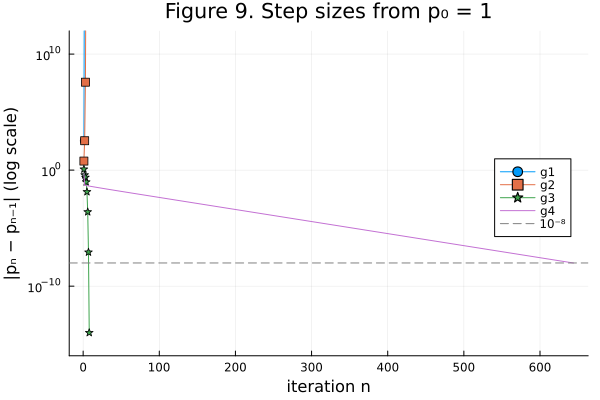

In [34]:
pl = plot(yaxis=:log10, xlabel="iteration n", ylabel="|pₙ − pₙ₋₁| (log scale)",
          ylims=(1e-16, 1e12), legend=:right,
          title="Figure 9. Step sizes from p₀ = 1")
markers = [:circle, :square, :star5, :none]
for i in 1:4
    steps = abs.(diff(runs[i][1]))
    good = isfinite.(steps) .& (steps .> 0)
    plot!(pl, (1:length(steps))[good], steps[good], marker=markers[i], ms=4, label="g$i")
end
hline!(pl, [1e-8], color=:gray, linestyle=:dash, label="10⁻⁸")
pl

*Figure 9. Step size $|p_n-p_{n-1}|$ (log scale) for the four fixed-point maps from $p_0=1$. $g_1$ and $g_2$ blow up within a few steps and leave the top of the plot. $g_3$ (Newton) drops below $10^{-8}$ at $n=8$. $g_4$ decreases along a straight line (linear convergence, rate $\approx0.976$) and needs 644 iterations.*

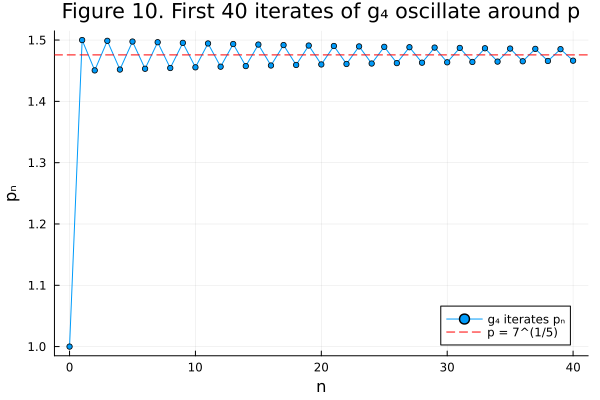

In [35]:
ps4 = runs[4][1]
plot(0:40, ps4[1:41], marker=:circle, ms=3, label="g₄ iterates pₙ", xlabel="n", ylabel="pₙ",
     title="Figure 10. First 40 iterates of g₄ oscillate around p")
hline!([p_fixed], color=:red, linestyle=:dash, label="p = 7^(1/5)")

*Figure 10. First 40 iterates of $g_4$ from $p_0=1$. They alternate above and below $p=7^{1/5}$ (red dashed), as expected from $g_4'(p)\approx-0.976<0$, and close in slowly.*

In [36]:
# for g4: is the step |p_n - p_{n-1}| a good estimate of the true error at the end?
@printf("g4 final: |p_n - p_{n-1}| = %.3e,  |p_n - p| = %.3e\n",
        abs(ps4[end] - ps4[end-1]), abs(ps4[end] - p_fixed))

g4 final: |p_n - p_{n-1}| = 9.890e-09,  |p_n - p| = 4.886e-09


**Analysis.**
* **$g_1$** exploded right away ($343$, then $\approx-2\times10^{25}$, then $\approx-3\times10^{253}$) and overflowed to `NaN` at $n=4$. **$g_2$** went $7,-336,3.8\times10^7,\dots$ and overflowed by $n=6$. Both diverged as predicted.
* **$g_3$** (Newton) converged in 8 iterations. Its steps in Figure 9 drop faster and faster, the signature of quadratic convergence.
* **$g_4$** converged, but needed **over 600 iterations**. Its steps decrease along a steady straight line on the semilog scale (linear convergence, factor $\approx0.976$), and Figure 10 shows the predicted alternation around $p$.
* **Differences from the local analysis.** Part (a) only describes $p_0$ *near* $p$. For $p_0=1$ the outcomes happened to agree in kind, but a few details go beyond it:
  1. $g_1$ and $g_2$ did not just drift away at rate 47 or 9.9 per step. Their first step from $p_0=1$ jumped far away immediately, and then global polynomial growth took over, which is much faster than the local rate.
  2. $g_4$'s iterates spent many steps *outside* the interval where $|g_4'(x)|<1$, which is only $0<|x|<(24/5)^{1/4}\approx1.4802$ (e.g. $p_1=1.5$, $p_3\approx1.4987$). It converged anyway. The local theorem gives a *sufficient* condition, not a necessary one.
  3. Linear convergence makes the step test less reliable. Here the final true error is about half of the last step, so stopping at $|p_n-p_{n-1}|<10^{-8}$ is fine. For a rate close to $+1$, though, the true error could be much larger than the step.

## 3(d) $g_3$ is Newton's method

Apply Newton to $F(x)=x^5-7$, with $F'(x)=5x^4$:
$$
x_{n+1}=x_n-\frac{F(x_n)}{F'(x_n)}=x_n-\frac{x_n^5-7}{5x_n^4}=g_3(x_n).
$$
So fixed-point iteration with $g_3$ **is** Newton's method for $x^5=7$.

**How this explains the behavior.** For Newton at a simple root, $g'(x)=\dfrac{F(x)F''(x)}{F'(x)^2}$, which is $0$ at $x=p$ because $F(p)=0$. That is the $g_3'(p)=0$ from part (a), and it is why $g_3$ converges quadratically, with constant
$$
\left|\frac{F''(p)}{2F'(p)}\right|=\frac{20p^3}{10p^4}=\frac{2}{p}\approx1.355 ,
$$
which equals $g_3''(p)/2$ from (a). $F$ is convex and increasing for $x>0$, so after the first step the iterates approach $p$ from above, as observed. The ratios below confirm the constant:

**Experiment (checking the predicted quadratic constant).**

In [37]:
ps3 = runs[3][1]
@printf("%3s  %22s  %12s  %20s\n", "n", "p_n", "|p_n - p|", "|e_n|/|e_{n-1}|^2")
for k in eachindex(ps3)
    e = abs(ps3[k] - p_fixed)
    r = k == 1 ? "—" : @sprintf("%.4f", e / abs(ps3[k-1] - p_fixed)^2)
    @printf("%3d  %22.16f  %12.4e  %20s\n", k - 1, ps3[k], e, r)
end
println("\npredicted constant 2/p = ", 2/p_fixed)

  n                     p_n     |p_n - p|     |e_n|/|e_{n-1}|^2
  0      1.0000000000000000    4.7577e-01                     —


  1      2.2000000000000002    7.2423e-01                3.1994
  2      1.8197636773444439    3.4399e-01                0.6558
  3      1.5834748298961614    1.0770e-01                0.9102
  4      1.4894609741454279    1.3688e-02                1.1800
  5      1.4760224361318610    2.4927e-04                1.3305
  6      1.4757732457766082    8.4182e-08                1.3548
  7      1.4757731615945617    9.5479e-15                1.3473
  8      1.4757731615945520    2.2204e-16    2435694768723.9028

predicted constant 2/p = 1.3552218268009617


**Analysis.** The ratio settles near $2/p\approx1.355$ as soon as the iterates are close, and it becomes meaningless once the error reaches machine precision.

## 3(e) Dependence on the initial guess (using $g_4$)

**Prediction.** $g_4$ converged from $p_0=1$, but part (a) only guarantees convergence *near* $p$, and $|g_4'(x)|<1$ only for $0<|x|<(24/5)^{1/4}\approx1.4802$. Far from $p$, $g_4(x)\approx-x^5/12$ grows much faster than $x$, so for large enough $|p_0|$ the iteration should diverge, with alternating signs.

**Implementation.** Reuse `fixed_point_history` from 3(c), unchanged: first for a list of starting values, then for a scan of $p_0\in[-3,3]$ with step $0.001$.

**Experiment.**

In [38]:
@printf("%7s  %-48s  %s\n", "p0", "result", "first iterates")
for p0 in (-1.0, 0.0, 1.0, 2.0, 2.1, 2.2, 2.3, 2.5, 3.0)
    ps, st = fixed_point_history(g4, p0)
    first4 = join([@sprintf("%.4g", x) for x in ps[2:min(5, end)]], ", ")
    @printf("%7.2f  %-48s  %s\n", p0, st, first4)
end

     p0  result                                            first iterates
  -1.00  converged at n = 679                              -0.3333, 0.2503, 0.8336, 1.383


   0.00  converged at n = 681                              0.5833, 1.161, 1.569, 1.361
   1.00  converged at n = 644                              1.5, 1.451, 1.499, 1.452
   2.00  converged at n = 677                              -0.08333, 0.5, 1.081, 1.541
   2.10  converged at n = 671                              -0.7201, -0.1206, 0.4627, 1.044
   2.20  converged at n = 665                              -1.511, -0.2709, 0.3126, 0.8957
   2.30  diverged: non-finite iterate (Inf) at n = 6       -2.48, 5.925, -602.1, 6.594e+12
   2.50  diverged: non-finite iterate (Inf) at n = 6       -5.055, 270.5, -1.207e+11, 2.134e+54
   3.00  diverged: non-finite iterate (-Inf) at n = 5      -16.67, 1.072e+05, -1.177e+24, 1.883e+119


g4 converges for p0 between -2.15

 and 2.268   (4419 of 6001 grid points)
Convergent set is a single interval: true


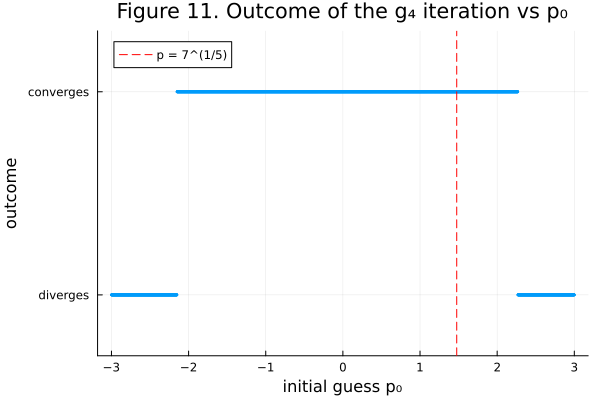

In [39]:
p0_scan = -3:0.001:3
outcome = [startswith(fixed_point_history(g4, p0; nmax=3000)[2], "converged") ? 1 : 0 for p0 in p0_scan]
conv = p0_scan[outcome .== 1]
println("g4 converges for p0 between ", minimum(conv), " and ", maximum(conv),
        "   (", length(conv), " of ", length(p0_scan), " grid points)")
println("Convergent set is a single interval: ", all(diff(findall(==(1), outcome)) .== 1))

scatter(p0_scan, outcome, ms=1.5, msw=0, label="", yticks=([0, 1], ["diverges", "converges"]),
        xlabel="initial guess p₀", ylabel="outcome", ylims=(-0.3, 1.3),
        title="Figure 11. Outcome of the g₄ iteration vs p₀")
vline!([p_fixed], color=:red, linestyle=:dash, label="p = 7^(1/5)")

*Figure 11. Outcome of the $g_4$ iteration for $p_0$ in `-3:0.001:3`. It converges only for $p_0\in[-2.15,\,2.268]$, a single interval containing $p$ (red dashed), and diverges everywhere else.*

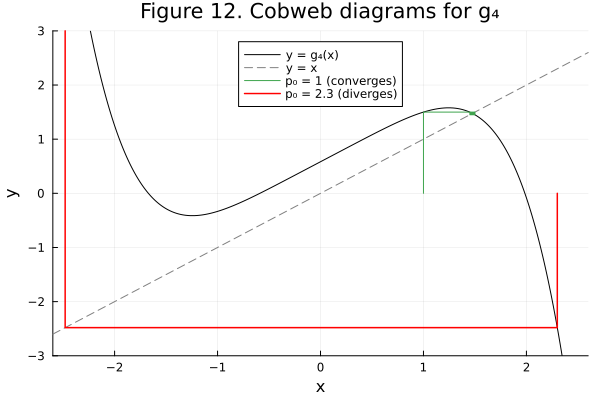

In [40]:
# cobweb diagram: one convergent and one divergent start
function cobweb!(plt, g, p0, nsteps; kw...)
    xs = [p0]; ys = [0.0]
    x = p0
    for _ in 1:nsteps
        y = g(x)
        push!(xs, x, y); push!(ys, y, y)
        x = y
    end
    plot!(plt, xs, ys; kw...)
end
xg = LinRange(-2.6, 2.6, 400)
cw = plot(xg, g4.(xg), label="y = g₄(x)", color=:black, xlabel="x", ylabel="y",
          ylims=(-3, 3), xlims=(-2.6, 2.6), legend=:top, title="Figure 12. Cobweb diagrams for g₄")
plot!(cw, xg, xg, label="y = x", color=:gray, linestyle=:dash)
cobweb!(cw, g4, 1.0, 30, label="p₀ = 1 (converges)", lw=1)
cobweb!(cw, g4, 2.3, 2, label="p₀ = 2.3 (diverges)", lw=1.5, color=:red)
cw

*Figure 12. Cobweb diagrams for $g_4$. From $p_0=1$ (green) the path spirals into the fixed point, where $y=g_4(x)$ meets $y=x$. From $p_0=2.3$ (red) the first step lands at about $-2.48$ and the next far above the plot, after which the iterates blow up with alternating signs.*

**Analysis.**
* **Yes, there is qualitatively different behavior.** Starting points in $[-2.15, 2.268]$ (including $-1$, $0$, $2$ and $2.2$) converge, all slowly with oscillation, in about 640–680 iterations. But $p_0=2.3$ gives $g_4(2.3)=2.3-(64.4-7)/12\approx-2.48$, then $g_4(-2.48)\approx5.9$, then $\approx-602$, and after that the iterates **blow up with alternating signs** and overflow by $n=6$. Figure 11 shows that the convergent starting points form one bounded interval, and everything outside it diverges.
* **This does not contradict part (a).** The local theorem says: if $|g'(p)|<1$, there is *some* neighborhood of $p$ from which the iteration converges. It says nothing about how big that neighborhood is. For $g_4$, $|g_4'(x)|<1$ only for $0<|x|<(24/5)^{1/4}\approx1.4802$, so $p\approx1.4758$ is within $0.005$ of where the contraction condition fails. For large $|x|$, $g_4(x)\approx-x^5/12$, so once $|x|$ is around $2.2$ or larger, $|g_4(x)|>|x|$ and every step makes the iterate bigger and flips its sign (Figure 12). The divergent starting points are simply outside the region of convergence. The local theorem never promised anything for them.

## 3(f) Verifying an AI claim

**Claim (from Claude):** the derivative values in 3(a): $g_1'(p)=1-15p^3\approx-47.21$, $g_2'(p)=1-5p^2\approx-9.890$, $g_3'(p)=0$, $g_4'(p)\approx-0.9764$. The $g_1$ computation is the easiest one to get wrong (chain rule plus the substitution $p^5=7$).

**Verification.** I re-derived $g_1'(p)$ by hand (shown in 3(a)), and checked all four values with a **centered finite difference**
$$
g'(p)\approx\frac{g(p+h)-g(p-h)}{2h},\qquad\text{error }O(h^2).
$$
This uses only the definitions of the $g_i$, not the derivative formulas. If the formulas are right, the difference should shrink about $100\times$ when $h$ shrinks $10\times$, until rounding error takes over.

In [41]:
@printf("%4s  %14s  %16s  %16s  %14s  %14s\n", "map", "formula", "FD h=1e-2", "FD h=1e-3", "diff h=1e-2", "diff h=1e-3")
for i in 1:4
    fd = h -> (gs[i](p_fixed + h) - gs[i](p_fixed - h)) / (2h)
    @printf("g%-3d  %14.8f  %16.8f  %16.8f  %14.2e  %14.2e\n", i, dg_exact[i], fd(1e-2), fd(1e-3),
            abs(fd(1e-2) - dg_exact[i]), abs(fd(1e-3) - dg_exact[i]))
end

 map         formula         FD h=1e-2         FD h=1e-3     diff h=1e-2     diff h=1e-3
g1      -47.21143775      -47.36866992      -47.21300981        1.57e-01        1.57e-03


g2       -9.88953212       -9.89003215       -9.88953712        5.00e-04        5.00e-06
g3        0.00000000       -0.00018369       -0.00000184        1.84e-04        1.84e-06
g4       -0.97636516       -0.97654666       -0.97636698        1.81e-04        1.81e-06


The finite differences agree with the formulas, and the discrepancy shrinks by about $100\times$ when $h$ goes from $10^{-2}$ to $10^{-3}$, consistent with $O(h^2)$. So the derivative values are confirmed.

**A weakness I checked for.** The copy of the assignment I first gave the AI had garbled formulas for $g_1,\dots,g_4$, and the AI *reconstructed* them. The check $g_i(p)-p\approx0$ in 3(a) is necessary but not sufficient, because many wrong formulas would also fix $p$. A finite-difference check would also "confirm" the derivative of a wrong formula. So the only real check is the source: I compared all four formulas, term by term, against the original assignment PDF, and they match exactly.